In [1]:
# Terminal
# !where pip
# !where python
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns


In [3]:
data_train = pd.read_csv('Dataset/train.csv')
data_test = pd.read_csv('Dataset/test.csv')

Performing EDA.

In [4]:
# Listing all the columns in the datasets

data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 57477 entries, 0 to 57476
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              57477 non-null  int64
 1   model_a         57477 non-null  str  
 2   model_b         57477 non-null  str  
 3   prompt          57477 non-null  str  
 4   response_a      57477 non-null  str  
 5   response_b      57477 non-null  str  
 6   winner_model_a  57477 non-null  int64
 7   winner_model_b  57477 non-null  int64
 8   winner_tie      57477 non-null  int64
dtypes: int64(4), str(5)
memory usage: 3.9 MB


In [5]:
# Shape of the datasets
print('Training data shape:', data_train.shape)
print('Test data shape:', data_test.shape)

Training data shape: (57477, 9)
Test data shape: (3, 4)


In [6]:
# Checking for missing values in the datasets
train_missing = data_train.isnull().sum()
test_missing = data_test.isnull().sum()

print('Missing values in training data:', train_missing.sum())
print('Missing values in test data:', test_missing.sum())

Missing values in training data: 0
Missing values in test data: 0


In [7]:
# Checking for recurring models in the data

print('Total distinct models in training data by model:', 
      data_train['model_a'].value_counts().sum(), data_train['model_b'].value_counts().sum())
print('\n')

print('Distinct models in training and testing data by model:')
print('Model A and B:', data_train['model_a'].nunique(), data_train['model_b'].nunique())

print('\n')

print('Recurring models in training data by model:')
print('Model A:', (data_train['model_a'].value_counts().sum())-data_train['model_a'].nunique())
print('Model B:', (data_train['model_b'].value_counts().sum())-data_train['model_b'].nunique())


Total distinct models in training data by model: 57477 57477


Distinct models in training and testing data by model:
Model A and B: 64 64


Recurring models in training data by model:
Model A: 57413
Model B: 57413


In [8]:
# Extracting the unique models from the training data
unique_models_a = data_train['model_a'].unique()
unique_models_b = data_train['model_b'].unique()

print('Are models in a and b are same:', set(unique_models_a) == set(unique_models_b))
print('\n')

print('Unique models in training data by model:')
unqiue_models = set(unique_models_a).union(set(unique_models_b))

unique_models = list(unqiue_models)
print(unique_models)


Are models in a and b are same: True


Unique models in training data by model:
['gpt-4-0613', 'gpt4all-13b-snoozy', 'pplx-7b-online', 'deepseek-llm-67b-chat', 'vicuna-13b', 'gpt-4-0314', 'oasst-pythia-12b', 'llama-13b', 'mistral-7b-instruct-v0.2', 'wizardlm-13b', 'fastchat-t5-3b', 'koala-13b', 'stripedhyena-nous-7b', 'claude-2.0', 'gpt-3.5-turbo-0613', 'qwen1.5-72b-chat', 'openhermes-2.5-mistral-7b', 'qwen1.5-7b-chat', 'RWKV-4-Raven-14B', 'openchat-3.5', 'pplx-70b-online', 'vicuna-7b', 'openchat-3.5-0106', 'dolphin-2.2.1-mistral-7b', 'gpt-3.5-turbo-0314', 'gpt-4-1106-preview', 'mpt-7b-chat', 'claude-1', 'tulu-2-dpo-70b', 'alpaca-13b', 'gemini-pro', 'llama-2-7b-chat', 'gemini-pro-dev-api', 'mixtral-8x7b-instruct-v0.1', 'vicuna-33b', 'yi-34b-chat', 'nous-hermes-2-mixtral-8x7b-dpo', 'chatglm-6b', 'starling-lm-7b-alpha', 'wizardlm-70b', 'mpt-30b-chat', 'mistral-medium', 'zephyr-7b-alpha', 'gpt-3.5-turbo-0125', 'llama-2-13b-chat', 'claude-2.1', 'llama-2-70b-chat', 'guanaco-33b', 'qwen-14b-

In [9]:
# Checking the distribution of the target variables in the training data
print('Distribution of target variable in training data:')

win_a = data_train['winner_model_a'].sum()
win_b = data_train['winner_model_b'].sum()
tie = data_train['winner_tie'].sum()

print('Proportion of wins for Model A:', win_a)
print('Proportion of wins for Model B:', win_b)
print('Proportion of ties:', tie)


target_distribution = data_train[['winner_model_a', 'winner_model_b', 'winner_tie']].value_counts(normalize=True)
print(target_distribution)

Distribution of target variable in training data:
Proportion of wins for Model A: 20064
Proportion of wins for Model B: 19652
Proportion of ties: 17761
winner_model_a  winner_model_b  winner_tie
1               0               0             0.349079
0               1               0             0.341911
                0               1             0.309011
Name: proportion, dtype: float64


In [10]:
# Creating a mini dataframe for unique models with respect to their win, lose and tie counts for train and test separately.

unique_models_distribution = pd.DataFrame(columns=['model', 'win_count', 'lose_count', 'tie_count'])

unique_models_distribution['model'] = unique_models

for model in unique_models:
    win_count = data_train[data_train['model_a'] == model]['winner_model_a'].sum() + data_train[data_train['model_b'] == model]['winner_model_b'].sum()
    lose_count = data_train[data_train['model_a'] == model]['winner_model_a'].sum() + data_train[data_train['model_b'] == model]['winner_model_b'].sum()
    tie_count = data_train[data_train['model_a'] == model]['winner_tie'].sum() + data_train[data_train['model_b'] == model]['winner_tie'].sum()
    unique_models_distribution.loc[unique_models_distribution['model'] == model, 'win_count'] = win_count
    unique_models_distribution.loc[unique_models_distribution['model'] == model, 'lose_count'] = lose_count
    unique_models_distribution.loc[unique_models_distribution['model'] == model, 'tie_count'] = tie_count

print('Unique models distribution in training data:')
print(unique_models_distribution)



Unique models distribution in training data:
                    model win_count lose_count tie_count
0              gpt-4-0613      2450       2450      1859
1      gpt4all-13b-snoozy        93         93       131
2          pplx-7b-online       328        328       353
3   deepseek-llm-67b-chat       190        190       276
4              vicuna-13b      1244       1244      1077
..                    ...       ...        ...       ...
59                 palm-2       637        637       544
60    mistral-7b-instruct       387        387       519
61            chatglm2-6b        73         73       171
62            chatglm3-6b       157        157       294
63       claude-instant-1      1642       1642      1214

[64 rows x 4 columns]


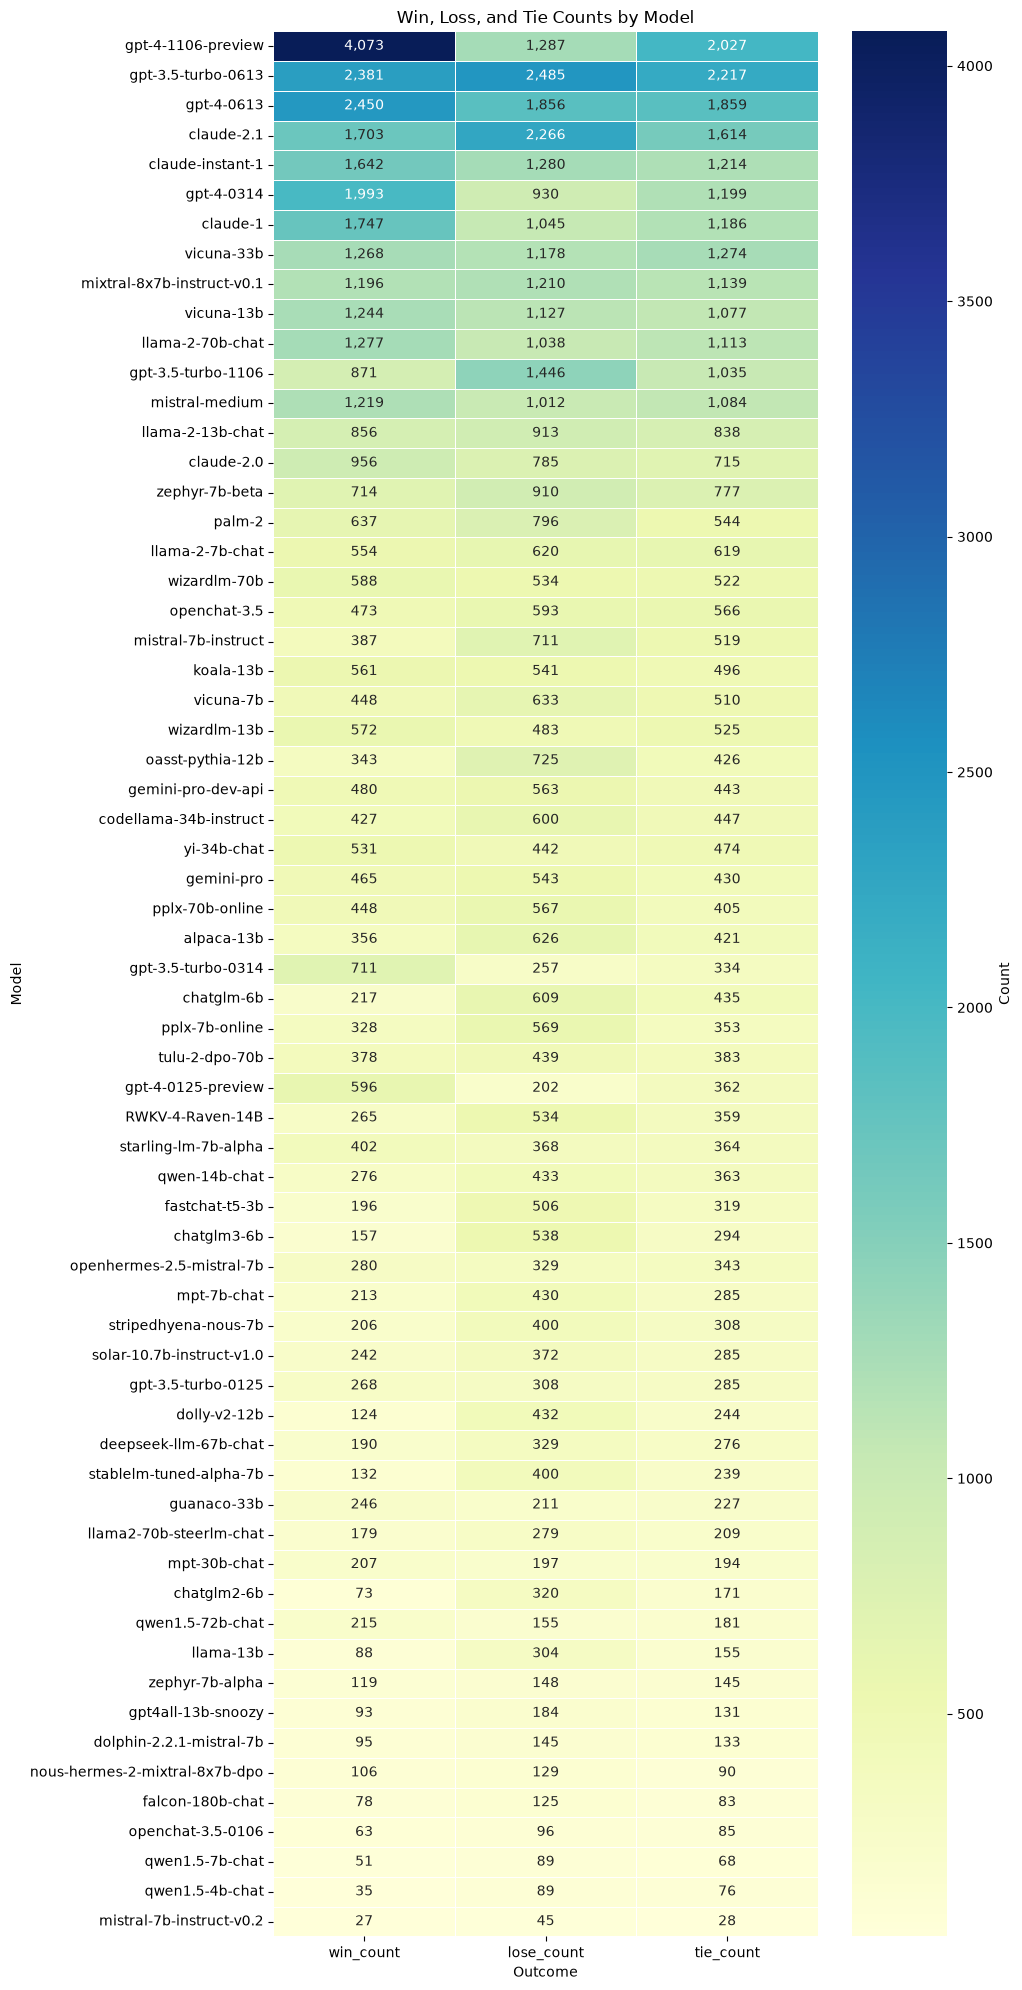

In [11]:
# Plotting the unique model distribution wrt to win, lose and tie in train data.
a = data_train.groupby('model_a').agg(  
    win_count=('winner_model_a', 'sum'),
    lose_count=('winner_model_b', 'sum'),
    tie_count=('winner_tie', 'sum')
)
b = data_train.groupby('model_b').agg(
    win_count=('winner_model_b', 'sum'),
    lose_count=('winner_model_a', 'sum'),
    tie_count=('winner_tie', 'sum')
)

plot_data = a.add(b).astype(int)
plot_data.index.name = 'model'
plot_data = plot_data.loc[
    plot_data.sum(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(10, 20))
sns.heatmap(
    plot_data,
    annot=True,
    fmt=',d',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_title('Win, Loss, and Tie Counts by Model')
ax.set_xlabel('Outcome')
ax.set_ylabel('Model')
plt.tight_layout()
plt.show()

In [12]:
# Checking the test dataset's models.

data_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          3 non-null      int64
 1   prompt      3 non-null      str  
 2   response_a  3 non-null      str  
 3   response_b  3 non-null      str  
dtypes: int64(1), str(3)
memory usage: 228.0 bytes


In [13]:
# Getting the models using Id from the test data

unique_models = pd.DataFrame(unique_models, columns=['model'])

test_model_samples = pd.concat([data_test[['id']], unique_models], axis=1, ignore_index=True).dropna()
test_model_samples

,0,1
0,136060.0,gpt-4-0613
1,211333.0,gpt4all-13b-snoozy
2,1233961.0,pplx-7b-online


In [14]:
# Checking submission file format


submission_format = pd.read_csv("Dataset/sample_submission.csv")
print(submission_format.head())

        id  winner_model_a  winner_model_b  winner_tie
0   136060        0.333333        0.333333    0.333333
1   211333        0.333333        0.333333    0.333333
2  1233961        0.333333        0.333333    0.333333


In [ ]:
# Calculating the probabilities of winning, losing, and tying for each model based on the training data.

counts = plot_data[['win_count', 'lose_count', 'tie_count']]
probabilities = counts.div(counts.sum(axis=1), axis=0)


sample_ids = test_model_samples.iloc[:, 0]
sample_models = test_model_samples.iloc[:, 1]


results = pd.DataFrame({
    'id': sample_ids.to_numpy().astype('int64'),
    'winner_model_a': sample_models.map(probabilities['win_count']).to_numpy(),
    'winner_model_b': sample_models.map(probabilities['lose_count']).to_numpy(),
    'winner_tie': sample_models.map(probabilities['tie_count']).to_numpy()
})


print('Sample submission results:')
print(results.head())

Sample submission results:
        id  winner_model_a  winner_model_b  winner_tie
0   136060        0.397405        0.301054    0.301541
1   211333        0.227941        0.450980    0.321078
2  1233961        0.262400        0.455200    0.282400


In [23]:
# Saving the results to a CSV file for submission
results.to_csv('submission.csv', index=False)

In [24]:
# Checking the submission format
print(type(results))

<class 'pandas.DataFrame'>


In [32]:
# Following the submission gudelines and error checks.

target_cols = ['winner_model_a', 'winner_model_b', 'winner_tie']

final_results = results.set_index('id').reindex(data_test['id'])
submission_format.loc[:, target_cols] = final_results[target_cols].to_numpy()
submission = submission_format.copy()
# submission[target_cols] = data_train[target_cols].mean().to_numpy()
submission[target_cols] = final_results[target_cols].to_numpy()

assert submission.columns.tolist() == submission_format.columns.tolist()
assert len(submission) == len(submission_format)
assert submission[target_cols].notna().all().all()

# submission.to_csv('/kaggle/working/submission.csv', index=False)
submission.to_csv('submission.csv', index=False)


In [33]:
submission.head()

,id,winner_model_a,winner_model_b,winner_tie
0,136060,0.397405,0.301054,0.301541
1,211333,0.227941,0.450980,0.321078
2,1233961,0.262400,0.455200,0.282400
